# 05 - Palabras clave (KeyBERT) y clustering (K-means)

**Objetivo:** segunda aproximación a los tópicos. Se extraen **palabras clave** de cada tweet, se representan los tweets a partir de ellas, se agrupan con **K-means** y los grupos se **nombran a mano**.

Qué responde:
1. ¿Qué palabras clave extrae KeyBERT y qué tan buenas son?
2. ¿Cómo representar un tweet a partir de sus palabras clave?
3. ¿Cuántos clusters usar?
4. ¿Qué tópicos se proponen a mano?
5. ¿Aparecen los eventos?

#### Dependencias

In [1]:
import time
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
import torch
from bertopic.vectorizers import ClassTfidfTransformer
from keybert import KeyBERT
from scipy.cluster.hierarchy import dendrogram, linkage
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

import utils
from eventos import EVENTOS

warnings.filterwarnings("ignore", category=FutureWarning)

#### Parámetros

In [2]:
RANDOM_STATE = 42
HILOS = 8

# KeyBERT
TOP_N = 3               # palabras clave por tweet
DIVERSIDAD_MMR = 0.5    # 0 = las más parecidas al tweet; 1 = las más distintas entre sí
MIN_DF = 10             # mismo vocabulario candidato que el vectorizador de BERTopic

# K-means
KS = [10, 20, 30, 40, 50, 75, 100]
N_BARRIDO = 50_000      # tweets para el barrido de K (el K-means completo tarda ~3 min por K)
N_SILHOUETTE = 10_000   # la silhouette compara todos contra todos: se calcula sobre una muestra
K_FINAL = 50

FILE_CLAVES = utils.PROCESSED_DIR / "palabras_clave.csv.gz"
FILE_CLUSTERS = utils.PROCESSED_DIR / "clusters_kmeans.csv"

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
torch.set_num_threads(HILOS)
rng = np.random.default_rng(RANDOM_STATE)

#### Funciones

In [3]:
def palabras_por_grupo(grupos, k, n=10):
    """Top-n términos de cada cluster con c-TF-IDF: el mismo criterio que usa BERTopic
    para nombrar tópicos, así la comparación mide solo el agrupamiento."""
    validos = np.where(grupos >= 0)[0]
    indicadora = sp.csr_matrix((np.ones(len(validos)), (grupos[validos], validos)), shape=(k, len(docs)))
    puntajes = ClassTfidfTransformer(reduce_frequent_words=True).fit_transform(indicadora @ X_conteo).toarray()
    return [[vocab[j] for j in np.argsort(-puntajes[c])[:n]] for c in range(k)]


def kmeans_ordenado(X, k, n_init):
    """K-means con los clusters numerados por tamaño (0 = el más grande)."""
    km = KMeans(k, n_init=n_init, random_state=RANDOM_STATE).fit(X)
    orden = np.argsort(-np.bincount(km.labels_, minlength=k))
    nuevo = np.empty(k, int)
    nuevo[orden] = np.arange(k)
    return nuevo[km.labels_], km.cluster_centers_[orden], km.inertia_


def metricas(grupos, X, k):
    """Mismas métricas que en la 04 (más silhouette, propia de K-means)."""
    con = np.where(grupos >= 0)[0]
    s = rng.choice(con, N_SILHOUETTE, replace=False)
    palabras = palabras_por_grupo(grupos, k)
    ev = utils.evaluar_eventos(grupos, textos, muestra["dia"], EVENTOS)
    return {
        "silhouette": silhouette_score(X[s], grupos[s], metric="cosine"),
        "NPMI": np.nanmean(utils.coherencia_npmi(palabras, X_bin, vocab)),
        "coherencia embeddings": np.nanmean(utils.coherencia_embeddings(palabras, modelo_emb)),
        "diversidad": utils.diversidad(palabras),
        "% en el cluster más grande": np.bincount(grupos[con]).max() / len(con) * 100,
        "eventos aislados": int(ev["aislado"].sum()),
    }

## 1. Datos

In [4]:
muestra = utils.cargar_muestra()
emb = utils.cargar_embeddings(len(muestra))
docs = muestra["texto_limpio"].tolist()
textos = muestra["texto_limpio"].str.lower()
modelo_emb = SentenceTransformer(utils.MODELO_EMBEDDINGS, device="cpu")

# Mismo vectorizador que BERTopic: define las palabras candidatas y el c-TF-IDF
vectorizador = CountVectorizer(stop_words=utils.STOPWORDS, token_pattern=utils.TOKEN_PATTERN,
                               ngram_range=(1, 2), min_df=MIN_DF)
X_conteo = vectorizador.fit_transform(docs)
vocab = vectorizador.get_feature_names_out()
X_bin = X_conteo.copy()
X_bin.data[:] = 1
X_bin = X_bin.tocsc()
print(f"{len(docs):,} tweets | vocabulario candidato: {len(vocab):,} términos (uni y bigramas)")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

217,133 tweets | vocabulario candidato: 18,323 términos (uni y bigramas)


## 2. Palabras clave con KeyBERT

Cómo funciona KeyBERT:
1. **Candidatos:** las palabras y pares de palabras del tweet que están en el vocabulario (sin stopwords).
2. **Embeddings:** cada candidato se convierte en vector con el mismo modelo que los tweets (`all-MiniLM-L6-v2`). Los embeddings de los tweets se reutilizan de la 03.
3. **Puntaje:** **similitud coseno** entre el candidato y el tweet. Una palabra clave es la que mejor resume el significado del tweet.
4. **MMR** (*Maximal Marginal Relevance*): elige las palabras de a una, balanceando parecido con el tweet y diferencia con las ya elegidas. Evita devolver `swine`, `swine flu` y `flu` juntas.

Se eligen **3 palabras clave por tweet**: con 12 palabras de mediana, más de 3 empieza a repetir el tweet entero.

In [5]:
if FILE_CLAVES.exists():
    guardado = pd.read_csv(FILE_CLAVES, keep_default_na=False)
    assert (guardado["id"].to_numpy() == muestra["id"].to_numpy()).all()
    claves = [[(w, float(s)) for w, s in zip(p.split("|"), q.split("|"))] if p else []
              for p, q in zip(guardado["palabras_clave"], guardado["puntajes"])]
    print("Palabras clave cargadas de", FILE_CLAVES.name)
else:
    inicio = time.time()
    claves = KeyBERT(model=modelo_emb).extract_keywords(
        docs, vectorizer=vectorizador, top_n=TOP_N, use_mmr=True, diversity=DIVERSIDAD_MMR, doc_embeddings=emb)
    print(f"KeyBERT: {(time.time() - inicio) / 60:.1f} min")
    pd.DataFrame({"id": muestra["id"],
                  "palabras_clave": ["|".join(w for w, _ in k) for k in claves],
                  "puntajes": ["|".join(f"{s:.4f}" for _, s in k) for k in claves]}).to_csv(FILE_CLAVES, index=False)

tiene_claves = np.array([len(k) > 0 for k in claves])
print(f"Tweets sin ninguna palabra clave: {(~tiene_claves).sum():,} ({(~tiene_claves).mean():.1%})")

Palabras clave cargadas de palabras_clave.csv.gz
Tweets sin ninguna palabra clave: 1,564 (0.7%)


In [6]:
ejemplos = muestra.sample(10, random_state=RANDOM_STATE).index
utils.con_traduccion(pd.DataFrame({
    "tweet": muestra.loc[ejemplos, "texto_limpio"],
    "palabras clave (similitud coseno)": [", ".join(f"{w} ({s:.2f})" for w, s in claves[i]) for i in ejemplos],
}), "tweet")

,tweet,traducción,palabras clave (similitud coseno)
129375,"Oh well, those are still good!","Bueno, ¡igual están buenos!","oh good (0.42), good (0.28), oh (0.28)"
150720,ohmygosh my eyes r soo red and starting to swell! allergy or hayfever wh knows? not happy,"¡Dios mío, tengo los ojos re rojos y se me empiezan a hinchar! ¿Alergia o fiebre del heno? Quién sabe. Nad...","allergy (0.59), hayfever (0.43), eyes (0.33)"
205577,Im painting that house this weekend.. but wow I am getting burned out doing labor all day all week,"Este fin de semana pinto esa casa... pero uf, me estoy quemando de tanto laburar todo el día toda la semana.","painting (0.52), labor (0.35), burned (0.28)"
118441,on the way to the studio. Loving the weather on the ride there - dont forget to tune in at 3pm.,Yendo al estudio. Me encanta el clima en el camino. ¡No se olviden de sintonizar a las 3 de la tarde!,"loving weather (0.42), studio (0.36), ride (0.35)"
81108,"Go0dmorning. Just got out of bed , about to cook breakfast. KInda lazy this Am...but hopefully I snap out ...","Buen día. Recién me levanto, voy a hacer el desayuno. Medio fiaca esta mañana... pero ojalá se me pase.","breakfast (0.51), lazy (0.38), just got (0.19)"
133165,A radio DJ said he wish would come to Manila! I literally crossed my fingers to that. Please do because I ...,"¡Un DJ de la radio dijo que ojalá vinieras a Manila! Literalmente crucé los dedos. Por favor vení, porque ...","manila (0.61), wish come (0.33), radio (0.29)"
197995,Omg. Cleaning out my car was like cleaning up after world war 2!!,Dios. ¡Limpiar mi auto fue como limpiar después de la Segunda Guerra Mundial!,"cleaning (0.50), car (0.30), omg (0.29)"
216809,god damn it I want a fuckin beagle so bad,"La puta madre, quiero un beagle con todas mis ganas.","damn want (0.33), fuckin (0.26), god (0.16)"
132837,i wish you'd reply me,Ojalá me respondieras.,"wish (0.50), reply (0.49), you'd (0.40)"
24500,oh the other men in our lives,"Ay, los otros hombres de nuestras vidas.","men (0.53), oh (0.36), lives (0.32)"


In [7]:
# Tweets de eventos: ¿la palabra clave captura el evento?
for patron in ["farrah fawcett", "air france", "swine flu"]:
    i = muestra.index[textos.str.contains(patron)][3]
    tweet = muestra.loc[i, "texto_limpio"]
    print(f"{tweet}\n   ({utils.traducir([tweet])[0]})\n   -> {claves[i]}\n")

Seen reports that Farrah Fawcett are close to death.
   (Vi noticias de que Farrah Fawcett está cerca de morir.)
   -> [('farrah fawcett', 0.7212), ('death', 0.3125), ('seen', 0.1304)]



just said a prayer for the passengers of the missing Air France jet
   (Acabo de rezar por los pasajeros del avión desaparecido de Air France.)
   -> [('prayer', 0.4946), ('air france', 0.4481), ('passengers', 0.3449)]

Build up you immune system to prevent the Swine Flu or its lab name H1N1. Eat more ham! LOL
   (Fortalecé tu sistema inmune para prevenir la gripe porcina, o como se llama en el laboratorio, H1N1. ¡Comé más jamón! JAJA)
   -> [('swine flu', 0.6192), ('ham', 0.4913), ('prevent', 0.2682)]



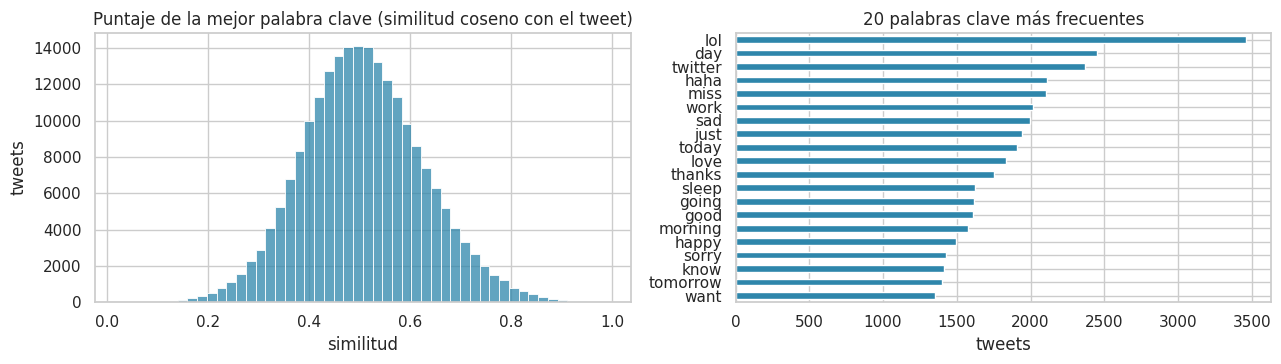

Mejor palabra clave: mediana 0.50; 4% de los tweets por debajo de 0,3


In [8]:
mejor = np.array([k[0][1] for k in claves if k])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.histplot(mejor, bins=50, ax=axes[0], color="#2e86ab")
axes[0].set(title="Puntaje de la mejor palabra clave (similitud coseno con el tweet)", xlabel="similitud", ylabel="tweets")
frecuentes = pd.Series(Counter(w for k in claves for w, _ in k)).nlargest(20)
frecuentes.sort_values().plot.barh(ax=axes[1], color="#2e86ab")
axes[1].set(title="20 palabras clave más frecuentes", xlabel="tweets")
plt.tight_layout()
plt.show()

print(f"Mejor palabra clave: mediana {np.median(mejor):.2f}; "
      f"{(mejor < 0.3).mean():.0%} de los tweets por debajo de 0,3")

- La mediana de la mejor palabra clave es ~0,50 y solo el 4% queda por debajo de 0,3: en general resume bien el tweet. Los puntajes bajos son tweets sin tema claro.
- En tweets de eventos, **el evento aparece entre las palabras clave** (`air france`, `swine flu`), aunque no siempre primero: en *"just said a prayer for the passengers of the missing Air France jet"* («acabo de rezar por los pasajeros del avión desaparecido de Air France») gana `prayer`.
- Las más frecuentes vuelven a ser **la vida diaria y la conversación** (`lol`, `day`, `twitter`, `miss`, `work`, `sad`). Coincide con el EDA y con BERTopic.

## 3. Representación de cada tweet

Para agrupar hace falta un vector por tweet. Se comparan dos formas de armarlo a partir de las palabras clave:

| | Representación | Qué captura |
| --- | --- | --- |
| **A** | Promedio de los **embeddings de sus palabras clave**, ponderado por el puntaje | Significado: `flu`, `fever` y `swine flu` quedan cerca aunque sean palabras distintas |
| **B** | **TF-IDF** sobre las palabras clave + **SVD** a 100 dimensiones | Coincidencia literal: dos tweets se parecen solo si comparten la misma palabra clave |

Los tweets sin palabras clave (0,7%) quedan afuera del clustering (cluster -1).

In [9]:
unicas = sorted({w for k in claves for w, _ in k})
emb_claves = dict(zip(unicas, modelo_emb.encode(unicas, batch_size=64, normalize_embeddings=True,
                                                show_progress_bar=False)))

rep_A = np.zeros((len(docs), emb.shape[1]), dtype=np.float32)
for i, k in enumerate(claves):
    if k:
        pesos = np.array([max(s, 0.01) for _, s in k])
        rep_A[i] = (pesos[:, None] * np.array([emb_claves[w] for w, _ in k])).sum(axis=0)
rep_A = normalize(rep_A)

tfidf = TfidfVectorizer(tokenizer=lambda s: [p for p in s.split("|") if p], lowercase=False,
                        token_pattern=None, min_df=5)
rep_B = normalize(TruncatedSVD(100, random_state=RANDOM_STATE).fit_transform(
    tfidf.fit_transform(["|".join(w for w, _ in k) for k in claves])))

con_claves = np.where(tiene_claves)[0]
print(f"Palabras clave distintas: {len(unicas):,} | A: {rep_A.shape} | B: {rep_B.shape}")

Palabras clave distintas: 18,281 | A: (217133, 384) | B: (217133, 100)


## 4. Elección de K

K-means necesita fijar K de antemano. Se prueba K entre 10 y 100 con la representación A, mirando:
- **Inercia** (suma de distancias al centroide): siempre baja al subir K. Se busca un **codo**.
- **Silhouette** (cohesión vs separación, de -1 a 1), con distancia coseno.

El barrido usa 50 mil tweets al azar para que sea rápido. El modelo final usa todos.

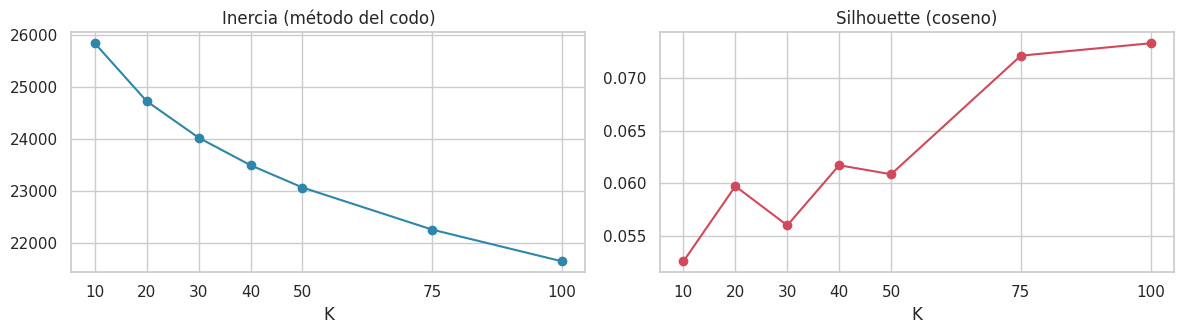

,inercia,silhouette
K,,
10,25837.9844,0.0526
20,24724.0273,0.0597
30,24023.7148,0.0560
40,23495.0059,0.0617
50,23066.9707,0.0609
75,22257.8926,0.0721
100,21648.8711,0.0733


In [10]:
barrido_idx = rng.choice(con_claves, N_BARRIDO, replace=False)
filas = []
for k in KS:
    grupos_k, _, inercia = kmeans_ordenado(rep_A[barrido_idx], k, n_init=3)
    s = rng.choice(len(barrido_idx), N_SILHOUETTE, replace=False)
    filas.append({"K": k, "inercia": inercia,
                  "silhouette": silhouette_score(rep_A[barrido_idx][s], grupos_k[s], metric="cosine")})
barrido = pd.DataFrame(filas).set_index("K")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
barrido["inercia"].plot(ax=axes[0], marker="o", color="#2e86ab", title="Inercia (método del codo)")
barrido["silhouette"].plot(ax=axes[1], marker="o", color="#d1495b", title="Silhouette (coseno)")
for ax in axes:
    ax.set_xticks(KS)
plt.tight_layout()
plt.show()
barrido.round(4)

- La inercia baja de forma pareja: **no hay un codo claro**, algo habitual en texto (los temas se superponen y no forman grupos esféricos separados).
- La silhouette es baja en todos los casos (< 0,08) y sube poco con K (de 0,05 a 0,07, con altibajos). Los tweets no forman grupos bien separados: hay un continuo de temas.
- **Se elige K = 50.** Las diferencias de silhouette entre valores de K son de centésimas (todas indican estructura débil), así que decide la interpretabilidad: 50 tópicos todavía se pueden **revisar y nombrar a mano**, que es el objetivo de este enfoque. Con 75 o 100 la silhouette sube ~0,01 y la revisión manual se vuelve inmanejable.

## 5. Representación A vs B (K = 50)

Se comparan con las mismas métricas de la 04. Las palabras de cada cluster salen del mismo c-TF-IDF que usa BERTopic.

In [11]:
modelos_km = {}
filas = []
for nombre, rep in [("A: embeddings de palabras clave", rep_A), ("B: TF-IDF + SVD", rep_B)]:
    inicio = time.time()
    grupos = np.full(len(docs), -1)
    grupos[con_claves], centros, _ = kmeans_ordenado(rep[con_claves], K_FINAL, n_init=5)
    modelos_km[nombre] = (grupos, centros)
    filas.append({"representación": nombre} | metricas(grupos, rep, K_FINAL) | {"segundos": time.time() - inicio})
pd.DataFrame(filas).set_index("representación").round(3)

,silhouette,NPMI,coherencia embeddings,diversidad,% en el cluster más grande,eventos aislados,segundos
representación,,,,,,,
A: embeddings de palabras clave,0.059,-0.17,0.518,0.986,5.293,1,234.531
B: TF-IDF + SVD,0.206,-0.37,0.273,0.962,15.281,0,31.643


- **B tiene mejor silhouette, pero es engañosa.** Muchos tweets comparten exactamente la misma palabra clave y quedan en el mismo punto, así que los clusters son "tweets que dicen X", más un cluster enorme con todo lo demás. Además, la silhouette mide distancias en espacios distintos y no se puede comparar entre representaciones.
- **A gana en lo que importa para interpretar:** palabras más coherentes (NPMI y embeddings), clusters más parejos y algún evento aislado.
- **Se usa la representación A.**

In [12]:
grupos, centros = modelos_km["A: embeddings de palabras clave"]
palabras = palabras_por_grupo(grupos, K_FINAL)

## 6. Tópicos propuestos a mano

Para nombrar cada cluster se miraron sus palabras c-TF-IDF, sus palabras clave más frecuentes y tweets de ejemplo. Los nombres se asocian a la **primera palabra c-TF-IDF** de cada cluster (no al número), así no se mezclan si el orden cambia.

In [13]:
NOMBRES = {
    "ng": "Misceláneo (votos, juegos, charla suelta)", "hate": "Emociones y relaciones",
    "london": "Lugares y ciudades", "know": "Opiniones y acuerdo", "eating": "Comida",
    "david": "Personas por nombre (Jonas, Idol, Carradine)", "hair": "Ropa, pelo y apariencia",
    "sleep": "Dormir", "send": "Mensajes y conexión online", "thanks": "Agradecimientos y felicitaciones",
    "book": "Lectura, escritura y tareas", "movie": "Películas y TV", "kate": "Famosos (Jon & Kate, Miley, Farrah)",
    "room": "Lugares cotidianos (casa, compras, hospital)", "tomorrow": "Planes (hoy, mañana, esta noche)",
    "song": "Música", "yeah": "Respuestas cortas", "haha": "Risas", "blog": "Internet y redes (blog, Facebook)",
    "laptop": "Computadoras", "twitter": "Twitter (la plataforma)", "exam": "Exámenes y escuela",
    "day": "Cómo va el día", "gym": "Deporte y ejercicio", "sad": "Tristeza y empatía", "work": "Trabajo",
    "friday": "Días de la semana", "night": "Buenas noches", "rain": "Lluvia y clima", "tweet": "Tuitear",
    "coffee": "Bebidas (café, cerveza)", "car": "Transporte", "dog": "Mascotas", "morning": "Buenos días",
    "headache": "Dolores", "miss": "Extrañar", "going": "Salidas y viajes", "bored": "Aburrimiento y cansancio",
    "iphone": "Celulares (iPhone, BlackBerry)", "sun": "Sol y verano", "feel": "Cómo se siente",
    "concert": "Eventos sociales (recitales, bodas)", "home": "Volver a casa",
    "flu": "Enfermedad (resfrío, gripe porcina)", "love": "Amor", "weekend": "Fin de semana y vacaciones",
    "leave": "Despedidas", "birthday": "Cumpleaños", "followers": "Seguidores de Twitter",
    "mother's": "Día de la Madre y del Padre",
}
nombres = [NOMBRES.get(p[0], f"sin nombre ({p[0]})") for p in palabras]
assert len(set(nombres)) == K_FINAL, "Algún cluster quedó sin nombre o repetido"

clave_frec = [Counter(w for i in np.where(grupos == c)[0] for w, _ in claves[i]).most_common(5) for c in range(K_FINAL)]
pd.DataFrame({
    "nombre (a mano)": nombres,
    "tweets": np.bincount(grupos[con_claves], minlength=K_FINAL),
    "palabras c-TF-IDF": [", ".join(p[:6]) for p in palabras],
    "palabras clave más frecuentes": [", ".join(w for w, _ in c) for c in clave_frec],
})

,nombre (a mano),tweets,palabras c-TF-IDF,palabras clave más frecuentes
0,"Misceláneo (votos, juegos, charla suelta)",11410,"ng, vote, win, number, card, won","time, new, sorry, got, lol"
1,Emociones y relaciones,10498,"hate, life, heart, talk, scared, crying","hate, life, talk, friends, mom"
2,Lugares y ciudades,7953,"london, beach, la, city, vegas, san","beach, london, la, city, vegas"
3,Opiniones y acuerdo,7650,"know, true, agree, think, thought, funny","know, just, think, really, wish"
4,Comida,7407,"eating, eat, food, hungry, dinner, lunch","lunch, dinner, hungry, eating, breakfast"
5,"Personas por nombre (Jonas, Idol, Carradine)",7012,"david, jonas, danny, adam, nick, chris","david, danny, nick, jonas, tom"
6,"Ropa, pelo y apariencia",6660,"hair, wear, shoes, shirt, green, dress","hair, green, shirt, dress, shoes"
7,Dormir,6632,"sleep, asleep, bed, nap, sleeping, slept","sleep, bed, sleeping, nap, slept"
8,Mensajes y conexión online,6216,"send, message, sent, online, link, let know","want, need, just, got, did"
9,Agradecimientos y felicitaciones,5952,"thanks, thank, glad, congrats, welcome, good luck","thanks, thank, happy, welcome, glad"


- Los 50 tópicos son **temas cotidianos amplios**: comida, dormir, trabajo, clima, mascotas, música, escuela, saludos, estados de ánimo.
- Varios se definen por **el tipo de mensaje**, no por el tema: risas (`lol`, `haha`), respuestas cortas (`yeah`, `cool`), agradecimientos. KeyBERT elige esas palabras porque en tweets sin tema son lo más representativo.
- Hay un cluster de **misceláneo** (el más grande) que junta tweets con palabras clave muy genéricas.

**Ejemplos de cada tópico.** Para respaldar los nombres, dos tweets por cluster: los más parecidos al centroide (similitud coseno en la representación A), con al menos 6 palabras.

In [ ]:
ejemplos_km = pd.DataFrame([
    {"tópico": nombres[c], "tweet": tw}
    for c in range(K_FINAL)
    for tw in utils.ejemplos_representativos(grupos == c, centros[c], rep_A, muestra["texto_limpio"])
])
with pd.option_context("display.max_rows", 120):
    display(utils.con_traduccion(ejemplos_km, "tweet"))

- Los ejemplos coinciden con los nombres: *Dormir* (*"didn't have enough sleep last night, i'm so sleepy"*, «anoche no dormí lo suficiente, tengo mucho sueño»), *Celulares* (*"yahoo + iPhone not working for me"*, «Yahoo + iPhone no me funciona»), *Día de la Madre y del Padre* (saludos a las mamás).
- También muestran los límites de agrupar por palabras clave. En *Personas por nombre* conviven un tweet sobre los Jonas Brothers y otro sobre la elección del presidente de la Cámara de los Comunes: los une que nombran personas, no el tema. En *Misceláneo*, los ejemplos son de juegos, pero el cluster junta charla muy variada.

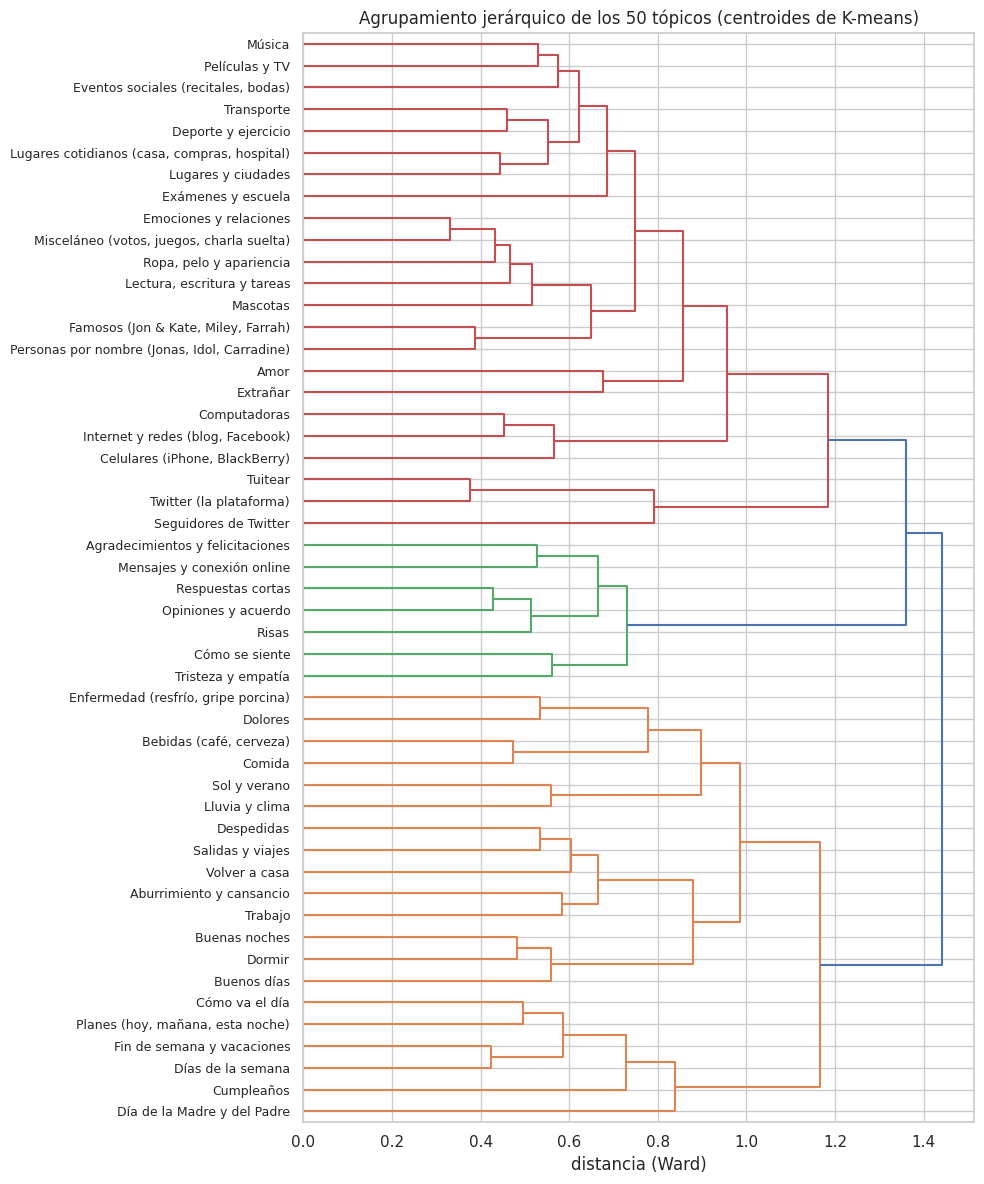

In [14]:
# Estructura entre tópicos: clustering jerárquico (Ward) sobre los 50 centroides
fig, ax = plt.subplots(figsize=(10, 12))
dendrogram(linkage(normalize(centros), method="ward"), labels=nombres, orientation="right",
           leaf_font_size=9, ax=ax, color_threshold=1.2)
ax.set(title="Agrupamiento jerárquico de los 50 tópicos (centroides de K-means)", xlabel="distancia (Ward)")
plt.tight_layout()
plt.show()

- El **clustering jerárquico** sobre los centroides muestra cómo se agrupan los tópicos en macrotemas. Se aplica a los 50 centroides y no a los 217 mil tweets, porque ese cálculo crece con el cuadrado de la cantidad de puntos.
- Se ven **tres ramas principales**:
  - **Tipo de mensaje** (verde): agradecimientos, respuestas cortas, risas, opiniones, cómo se siente, tristeza. Es conversación más que tema.
  - **Rutina y cuerpo** (naranja): dormir, buenos días y buenas noches, trabajo, comida y bebidas, clima, dolores y enfermedad, fines de semana y fechas especiales.
  - **Temas e intereses** (rojo): música, películas, eventos sociales, lugares, famosos, tecnología (computadoras, internet, celulares) y Twitter (tuitear, plataforma, seguidores).

## 7. ¿Aparecen los eventos?

Mismo análisis que en la 04: PMI cluster–día y evaluación contra los 34 eventos.

In [15]:
pmi, conteo = utils.pmi_grupo_dia(grupos, muestra["dia"], min_tweets=20)
temporal = pd.DataFrame({
    "nombre": [nombres[c] for c in pmi.index],
    "PMI máx": pmi.max(axis=1).round(2),
    "día del pico": pmi.idxmax(axis=1).dt.strftime("%d/%m"),
}).sort_values("PMI máx", ascending=False)
print(f"Clusters con PMI máx >= 3: {(temporal['PMI máx'] >= 3).sum()} de {K_FINAL}")
temporal.head(10)

Clusters con PMI máx >= 3: 1 de 50


,nombre,PMI máx,día del pico
grupo,,,
49,Día de la Madre y del Padre,4.25,10/05
38,"Celulares (iPhone, BlackBerry)",1.65,17/06
45,Fin de semana y vacaciones,1.42,22/05
24,Tristeza y empatía,1.25,22/06
26,Días de la semana,1.22,22/05
12,"Famosos (Jon & Kate, Miley, Farrah)",1.20,22/06
28,Lluvia y clima,1.14,18/06
35,Extrañar,1.13,24/06
33,Buenos días,1.05,04/05


In [16]:
validacion = utils.evaluar_eventos(grupos, textos, muestra["dia"], EVENTOS)
validacion["cluster"] = [nombres[int(g)] if pd.notna(g) else "" for g in validacion["grupo"]]
print(f"Eventos aislados: {validacion['aislado'].sum()} | confirmados: {validacion['confirmado'].sum()} de {len(validacion)}")
validacion[["evento", "tweets", "cluster", "precisión", "recall", "pico del grupo", "confirmado"]]

Eventos aislados: 1 | confirmados: 1 de 34


,evento,tweets,cluster,precisión,recall,pico del grupo,confirmado
0,Pascua,102,Comida,0.00,0.22,18/04,False
1,Oracle anuncia la compra de Sun,36,Sol y verano,0.00,0.31,31/05,False
2,Gripe porcina: la OMS sube la alerta a fase 4 y 5,236,"Enfermedad (resfrío, gripe porcina)",0.07,0.73,24/06,False
3,Estreno de X-Men Origins: Wolverine,137,"Personas por nombre (Jonas, Idol, Carradine)",0.01,0.58,04/06,False
4,Pelea Pacquiao–Hatton,29,"Personas por nombre (Jonas, Idol, Carradine)",0.00,0.59,04/06,False
5,Estreno de Star Trek,294,Películas y TV,0.04,0.75,31/05,False
6,Día de la Madre (EE. UU.),780,Día de la Madre y del Padre,0.64,0.93,10/05,True
7,Danny Gokey eliminado de American Idol,228,"Personas por nombre (Jonas, Idol, Carradine)",0.02,0.54,04/06,False
8,Final de Eurovisión,38,Música,0.00,0.45,17/05,False
9,Lanzamiento de Wolfram Alpha,18,"Lectura, escritura y tareas",0.00,0.28,21/04,False


- Solo el **Día de la Madre** queda como cluster propio y con pico en la fecha: es el único evento con suficientes tweets (y muy parecidos entre sí) para ocupar 1 de 50 clusters.
- Los demás eventos **se disuelven en clusters temáticos amplios**: Farrah Fawcett y Jon & Kate caen en *Famosos*; Carradine y *American Idol*, en *Personas por nombre*; Star Trek y Transformers, en *Películas y TV*; la gripe porcina, en *Enfermedad*; el iPhone OS 3, en *Celulares*; Air France, en *Transporte*; Irán y los Lakers, en *Lugares y ciudades*. El recall suele ser medio o alto (el evento queda junto), pero la precisión es mínima (el cluster habla de mucho más).
- Por eso las PMI cluster–día son bajas: un evento de un día apenas mueve la proporción de un cluster de 5 mil tweets. *Celulares* tiene su pico el 17/6 (iPhone OS 3) y *Famosos* el 22/6 (Jon & Kate), pero son picos débiles.
- Con K = 50, K-means encuentra **de qué se habla en general**, no **qué pasó cada día**.

## 8. Guardar

In [17]:
pd.DataFrame({"id": muestra["id"], "cluster": grupos,
              "nombre": [nombres[g] if g >= 0 else "sin palabras clave" for g in grupos]}).to_csv(FILE_CLUSTERS, index=False)
validacion.to_csv(utils.PROCESSED_DIR / "validacion_kmeans.csv", index=False)
print(FILE_CLUSTERS.name, "y", FILE_CLAVES.name, "guardados")

clusters_kmeans.csv y palabras_clave.csv.gz guardados


## 9. Conclusiones parciales

| Pregunta | Respuesta |
| --- | --- |
| ¿KeyBERT extrae buenas palabras clave? | Sí: en tweets con tema, la palabra clave es el tema (`farrah`, `swine flu`). En tweets sin tema, elige la palabra más representativa del tipo de mensaje (`lol`, `thanks`) |
| ¿Qué representación? | **A: promedio de embeddings de las palabras clave**. Agrupa por significado; B agrupa por coincidencia literal y deja un cluster gigante |
| ¿Cuántos clusters? | **K = 50**: sin codo claro, silhouette casi en su máximo y una cantidad que se puede nombrar a mano |
| ¿Qué tópicos se proponen? | 50 temas cotidianos (comida, dormir, trabajo, clima, música, famosos, Twitter...), agrupables en macrotemas |
| ¿Aparecen los eventos? | Solo el Día de la Madre. El resto queda dentro de clusters temáticos amplios |

- **Fortalezas:** tópicos **fáciles de interpretar y nombrar**, todos los tweets asignados (sin outliers) y control total sobre la cantidad de tópicos.
- **Debilidades:** hay que elegir K sin un criterio claro, la silhouette es baja y, con un K manejable a mano, **los eventos se diluyen**. Para encontrarlos habría que subir mucho K, y entonces se pierde la ventaja de poder nombrarlos a mano.